# Experiment 4: Regularization

**Aim:** Compare Ridge, Lasso and Elastic Net with ordinary regression.

      Model         MSE       R2
     Linear 2900.193628 0.452603
      Ridge 2892.014566 0.454147
      Lasso 2824.568094 0.466877
Elastic Net 2866.461255 0.458970


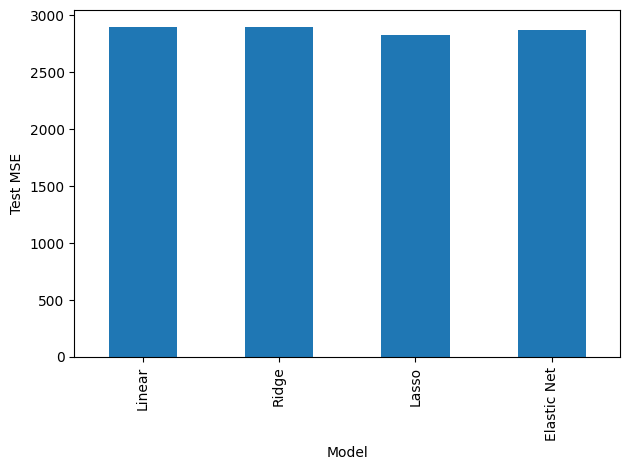

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet
from sklearn.metrics import mean_squared_error,r2_score
X,y=load_diabetes(return_X_y=True)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
models={'Linear':LinearRegression(),'Ridge':Ridge(alpha=1),'Lasso':Lasso(alpha=1),'Elastic Net':ElasticNet(alpha=.1,l1_ratio=.5)}
rows=[]
for name,reg in models.items():
    model=make_pipeline(StandardScaler(),reg).fit(X_train,y_train)
    pred=model.predict(X_test)
    rows.append([name,mean_squared_error(y_test,pred),r2_score(y_test,pred)])
results=pd.DataFrame(rows,columns=['Model','MSE','R2'])
print(results.to_string(index=False))
results.plot.bar(x='Model',y='MSE',legend=False); plt.ylabel('Test MSE'); plt.tight_layout(); plt.show()